In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile as zip

zip_path = '/content/drive/MyDrive/Projects/HeartFailurePrediction/archive.zip'
extract_path = '/content/drive/MyDrive/Projects/HeartFailurePrediction/Data'

with zip.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

In [3]:
data_path = '/content/drive/MyDrive/Projects/HeartFailurePrediction/Data/Heart_Disease_Prediction.csv'

In [4]:
!pip install seaborn

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [21]:
data = pd.read_csv(data_path)

In [8]:
data.head(10)

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence
5,65,1,4,120,177,0,0,140,0,0.4,1,0,7,Absence
6,56,1,3,130,256,1,2,142,1,0.6,2,1,6,Presence
7,59,1,4,110,239,0,2,142,1,1.2,2,1,7,Presence
8,60,1,4,140,293,0,2,170,0,1.2,2,2,7,Presence
9,63,0,4,150,407,0,2,154,0,4.0,2,3,7,Presence


In [9]:
data.tail(10)

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
260,58,0,3,120,340,0,0,172,0,0.0,1,0,3,Absence
261,60,1,4,130,206,0,2,132,1,2.4,2,2,7,Presence
262,58,1,2,120,284,0,2,160,0,1.8,2,0,3,Presence
263,49,1,2,130,266,0,0,171,0,0.6,1,0,3,Absence
264,48,1,2,110,229,0,0,168,0,1.0,3,0,7,Presence
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,Absence
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,Absence
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,Absence
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,Absence
269,67,1,4,160,286,0,2,108,1,1.5,2,3,3,Presence


In [10]:
data.shape

(270, 14)

In [14]:
target_col = "Heart Disease"

In [22]:
data[target_col] = data[target_col].map({"Presence" : 1, "Absence" : 0})

In [23]:
data.head(10)

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,1
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,0
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,1
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,0
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,0
5,65,1,4,120,177,0,0,140,0,0.4,1,0,7,0
6,56,1,3,130,256,1,2,142,1,0.6,2,1,6,1
7,59,1,4,110,239,0,2,142,1,1.2,2,1,7,1
8,60,1,4,140,293,0,2,170,0,1.2,2,2,7,1
9,63,0,4,150,407,0,2,154,0,4.0,2,3,7,1


Heart Disease
0    150
1    120
Name: count, dtype: int64


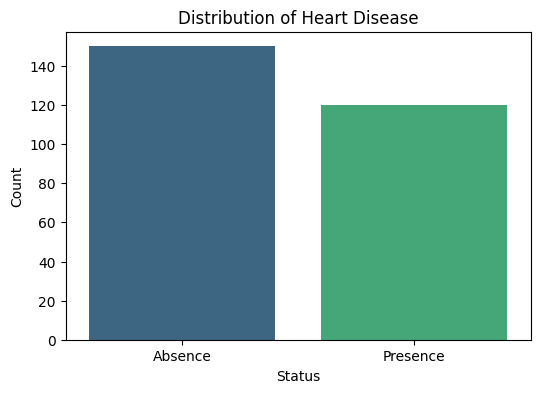

In [24]:
class_counts = data[target_col].value_counts()
print(class_counts)

plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index.map({1: 'Presence', 0: 'Absence'}), y=class_counts.values, hue=class_counts.index.map({1: 'Presence', 0: 'Absence'}), palette='viridis', legend=False)
plt.title('Distribution of Heart Disease')
plt.xlabel('Status')
plt.ylabel('Count')
plt.show()

In [25]:
X = data.drop(target_col, axis=1)
y = data[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [27]:
clf = DecisionTreeClassifier(max_depth = 6, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=6, random_state=42)

In [28]:
y_pred = clf.predict(X_test)

In [29]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))


Accuracy: 0.7037037037037037
Precision: 0.6086956521739131
Recall: 0.6666666666666666
F1 Score: 0.6363636363636364


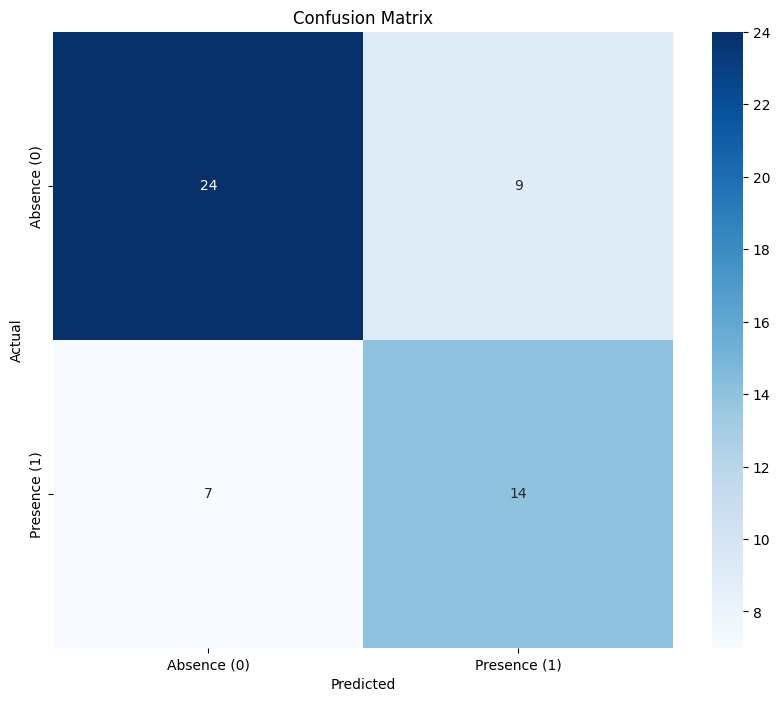

In [31]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [32]:
clf = DecisionTreeClassifier(max_depth = 8, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=8, random_state=42)

In [33]:
y_pred = clf.predict(X_test)

In [34]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7037037037037037
Precision: 0.5862068965517241
Recall: 0.8095238095238095
F1 Score: 0.68


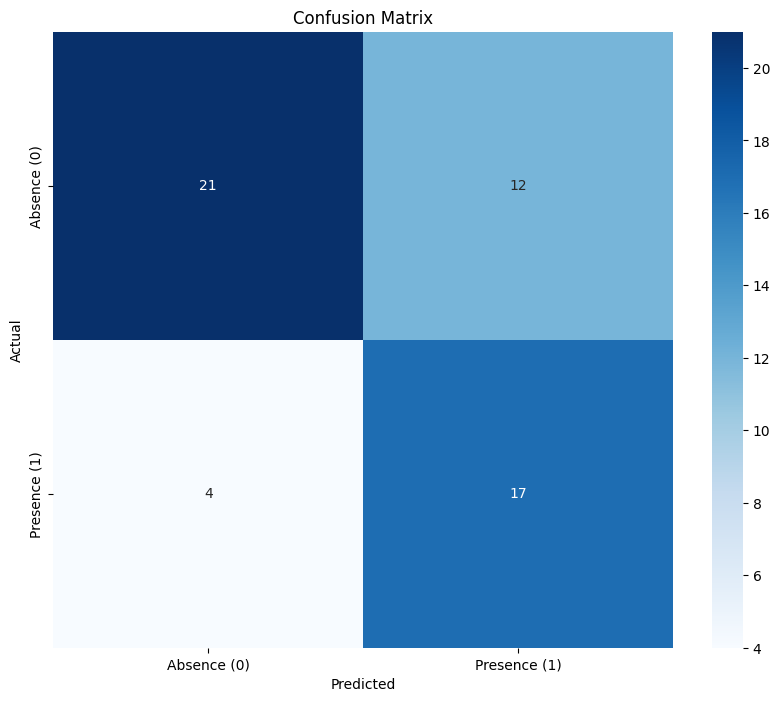

In [35]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [36]:
clf = DecisionTreeClassifier(max_depth = 4, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [37]:
y_pred = clf.predict(X_test)

In [38]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8703703703703703
Precision: 1.0
Recall: 0.6666666666666666
F1 Score: 0.8


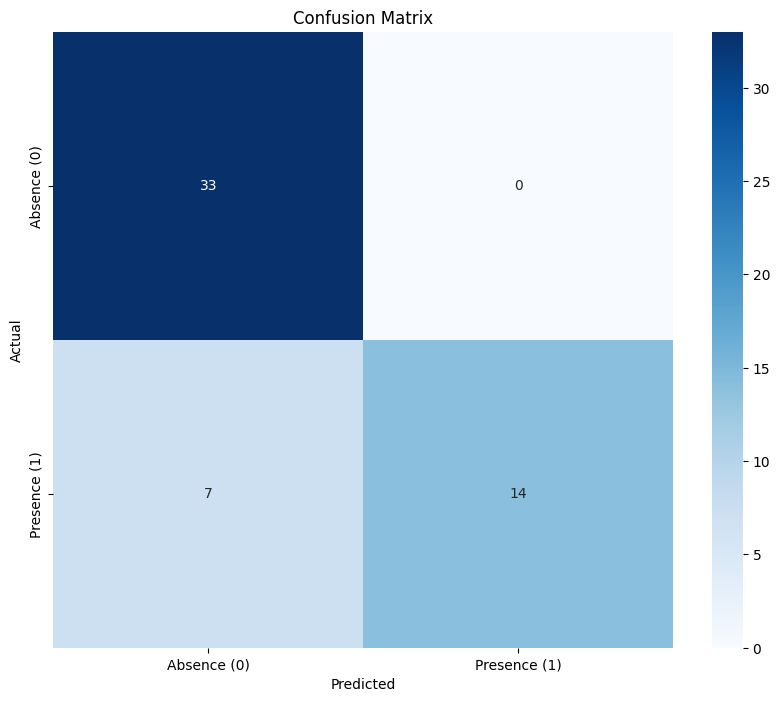

In [39]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [40]:
clf = DecisionTreeClassifier(max_depth = 3, random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [41]:
y_pred = clf.predict(X_test)

In [42]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7222222222222222
Precision: 0.65
Recall: 0.6190476190476191
F1 Score: 0.6341463414634146


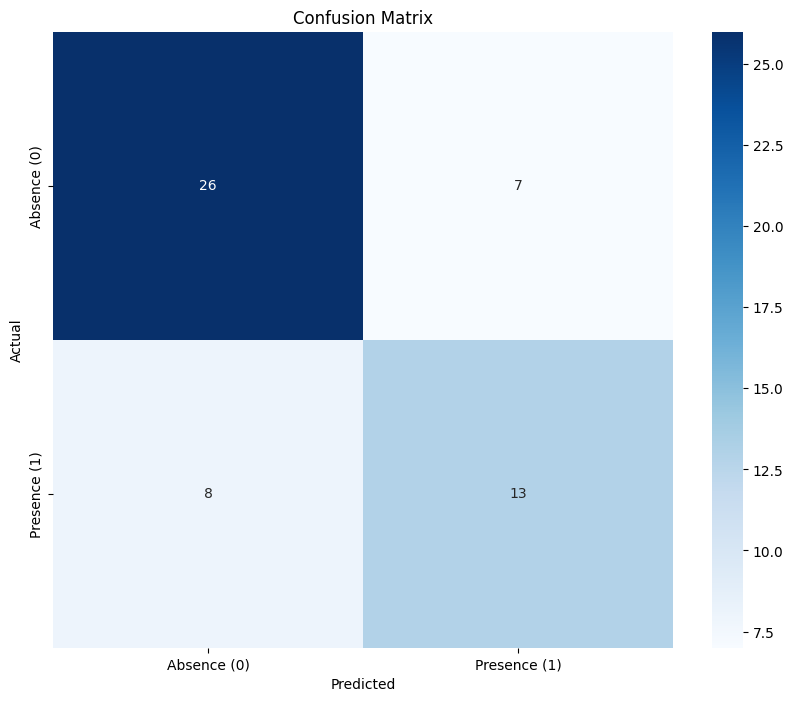

In [43]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [44]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [45]:
y_pred = rf.predict(X_test)

In [46]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7962962962962963
Precision: 0.7777777777777778
Recall: 0.6666666666666666
F1 Score: 0.717948717948718


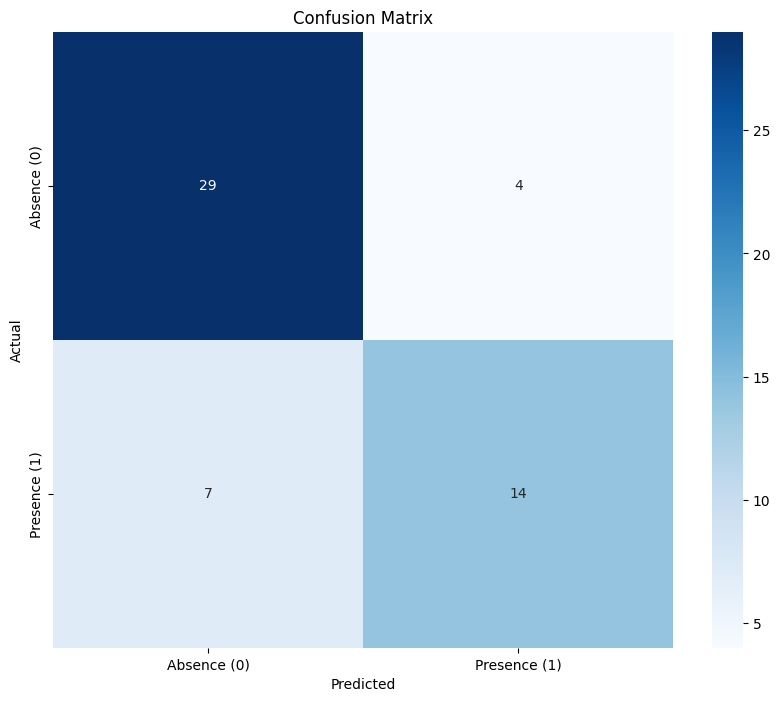

In [47]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [48]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [49]:
y_pred = rf.predict(X_test)

In [50]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8703703703703703
Precision: 0.8888888888888888
Recall: 0.7619047619047619
F1 Score: 0.8205128205128205


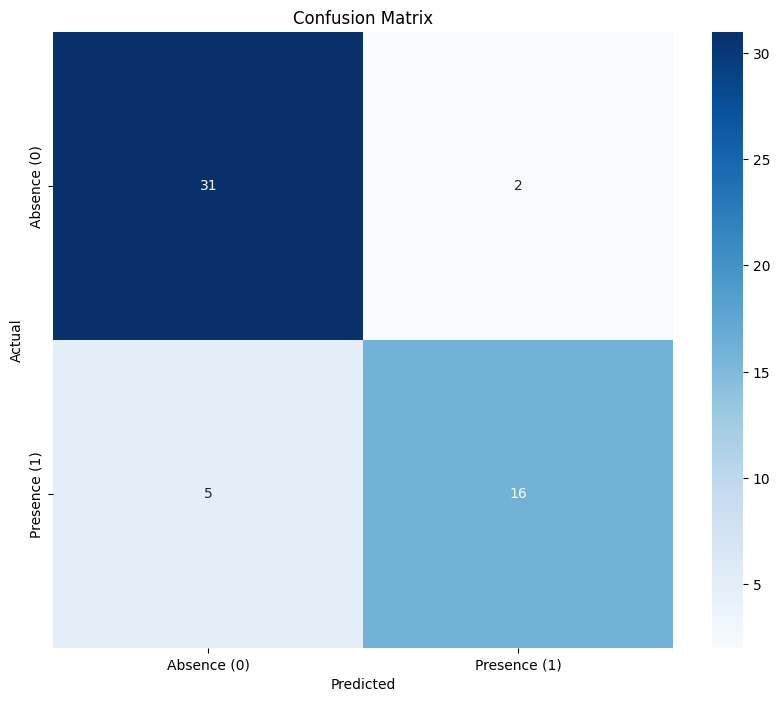

In [51]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [56]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

In [57]:
y_pred = rf.predict(X_test)

In [58]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8703703703703703
Precision: 0.9375
Recall: 0.7142857142857143
F1 Score: 0.8108108108108109


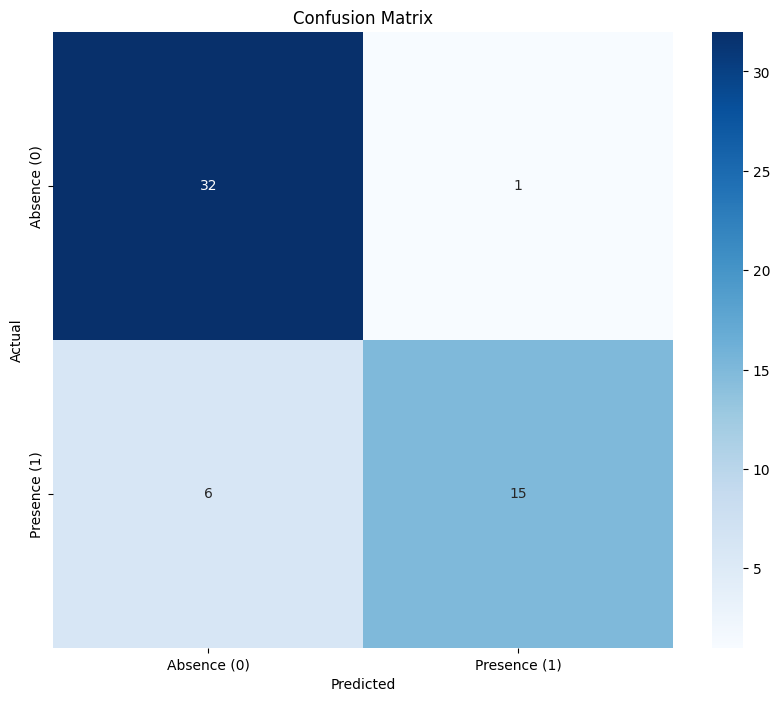

In [59]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [62]:
from sklearn.model_selection import GridSearchCV

In [60]:
param_grid = {
    'n_estimators': [100, 200, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
}

In [61]:
rf = RandomForestClassifier(random_state=42)

In [63]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 500]},
             scoring='accuracy')

In [64]:
print('Best parameters:', grid_search.best_params_)
print('Best validation results:', grid_search.best_score_)

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best validation results: 0.833615221987315


In [65]:
best_rf = grid_search.best_estimator_

In [66]:
print(best_rf)

RandomForestClassifier(min_samples_split=10, n_estimators=200, random_state=42)


In [68]:
rf = RandomForestClassifier(min_samples_split=10, n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(min_samples_split=10, n_estimators=200, random_state=42)

In [69]:
y_pred = rf.predict(X_test)

In [70]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8518518518518519
Precision: 0.8421052631578947
Recall: 0.7619047619047619
F1 Score: 0.8


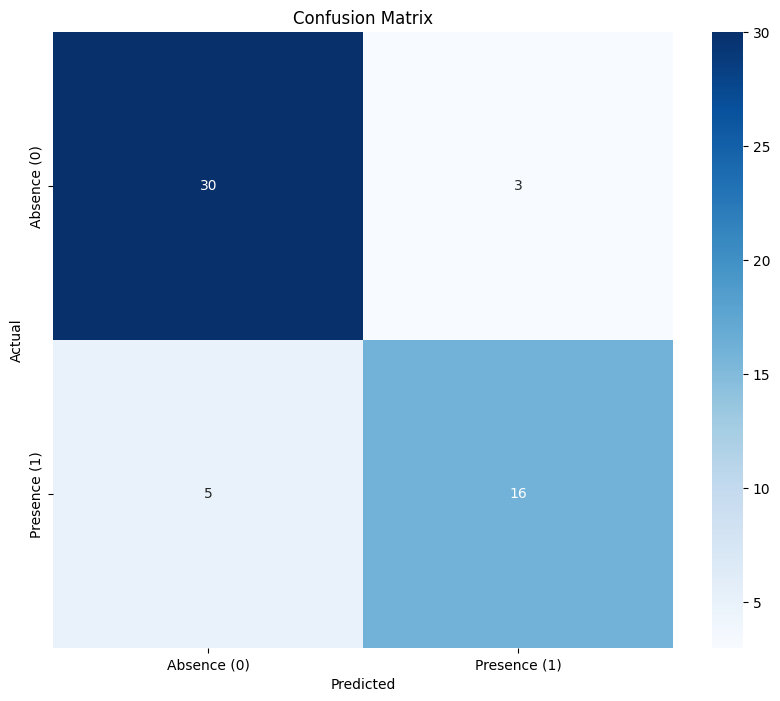

In [71]:
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=["Absence (0)", "Presence (1)"],
            yticklabels=["Absence (0)", "Presence (1)"])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()